# 06 — Modèles : de la mesure brute à la correction apprise

**But de ce notebook.** Comparer, sur les **mêmes 5 plis par station**, une échelle de modèles de plus en plus riches,
puis régler le meilleur (variables, échelle, contrainte, hyperparamètres) et mesurer ce qu'il apporte au regard des
cibles de l'EPA.

Les calculs sont lancés par `python -m aircalib train --study <étude>` et **enregistrés dans MLflow**
(`sqlite:///mlflow.db`, interface : `make mlflow`). Chaque run garde les paramètres, la liste des variables, l'empreinte
SHA-256 de la table gold, les métriques par pli et regroupées (horaire et journalier, en µg/m³, paires saines et toutes
paires) et, en artefacts, les prédictions hors pli et les figures. Ce notebook **relit** ces runs : il ne réentraîne rien.

**Protocole.**

- **Pli** : une station et toutes ses paires sont dans un seul des 5 plis. Pour le pli $k$, on entraîne sur la zone
  d'entraînement (Allemagne, ≤ 1,5 km, paires saines) des 4 autres plis et on prédit **toutes** les paires ≤ 1,5 km des
  stations du pli $k$, saines et invérifiables.
- **Modèle physique hors pli** : pour le pli $k$, $a$ et $\kappa$ sont ajustés sans le pli $k$, et les variables
  physiques de **toutes** les lignes (entraînement compris) sont recalculées avec ces valeurs.
- **Deux chiffres** pour chaque résultat : « paires saines » et « toutes paires » (les invérifiables, repérées grâce à la
  station, ne sont jamais apprises ; les exclure de l'évaluation serait optimiste).
- **Études annexes** (ablation, Optuna, X, échelle, contrainte, recalibration, invérifiables) : sur un
  **sous-échantillon fixe de 20 % des paires** (graine 42, le même partout), puis le réglage retenu est réentraîné sur le
  volume complet.
- Hors étape : test 2024 → 2025, test « distance » et transfert vers la France (étape 7).

## 0. Préparation

**Ce qu'on fait.** On charge la configuration et on définit trois petites fonctions qui relisent les runs MLflow sous
forme de tableaux : `table` (un run par ligne), `by_neighbours` (découpage « avec / sans voisins ») et `both` (paires
saines et toutes paires côte à côte).
**Pourquoi.** Tous les chiffres de ce notebook viennent des runs enregistrés : aucun calcul n'est refait ici, ce qui
garantit que le notebook montre exactement ce qui a été mesuré.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

from aircalib.config import get_settings
from aircalib.evaluation.health import threshold_cv
from aircalib.models import results

settings = get_settings()
FIG_DIR = settings.paths.reports_dir / "figures"
pl.Config.set_tbl_rows(70)
pl.Config.set_tbl_cols(16)
pl.Config.set_tbl_width_chars(180)
pl.Config.set_fmt_str_lengths(60)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
SUB, FULL = "sous-échantillon", "complet"


def table(parent, scope, subset="saines"):
    runs = results.children(settings, parent, scope)
    return runs, results.summary(runs, subset)


def by_neighbours(parent, scope, res="hourly"):
    # One row per run × pairs (sane / all) × hours (all / with / without neighbours).
    runs = results.children(settings, parent, scope)
    rows = []
    for rec in runs.iter_rows(named=True):
        for subset in ("saines", "toutes"):
            for nb in ("", "avec_voisins", "sans_voisins"):
                prefix = f"{res}_{subset}_{nb}_" if nb else f"{res}_{subset}_"
                if prefix + "rmse" not in rec or rec[prefix + "rmse"] is None:
                    continue
                rows.append(
                    {
                        "run": rec["run"],
                        "paires": subset,
                        "heures": nb or "toutes",
                        **{
                            m: rec.get(prefix + m)
                            for m in ("rmse", "mae", "r2", "slope", "intercept", "pct_epa_all", "pairs")
                        },
                    }
                )
    return pl.DataFrame(rows).with_columns(pl.col(pl.Float64).round(2))


def both(parent, scope, metrics=("rmse", "r2", "slope", "intercept", "pct_epa_all")):
    runs = results.children(settings, parent, scope)
    cols = ["run"]
    for res in ("hourly", "daily"):
        for subset in ("saines", "toutes"):
            cols += [f"{res}_{subset}_{m}" for m in metrics if f"{res}_{subset}_{m}" in runs.columns]
    return runs.select(cols).with_columns(pl.col(pl.Float64).round(2))

## 1. Les métriques EPA, et pourquoi la pente est la cible difficile

**Ce qu'on fait.** Pour chaque paire, la prédiction corrigée $\hat y$ est régressée sur la référence $y$ (convention EPA :
$\hat y = s\,y + b$). Une paire passe si $R^2 \ge 0{,}70$, $s \in [0{,}65 ; 1{,}35]$, $b \in [-5 ; 5]$ µg/m³ et
RMSE ≤ 7 µg/m³.

**Pourquoi la pente pose problème.** Un modèle entraîné à minimiser l'erreur quadratique est **calibré** au sens
$\mathbb{E}[y \mid \hat y] = \hat y$ : il est prudent et **resserre** ses prédictions vers la moyenne. Alors
$\operatorname{cov}(\hat y, y) = \operatorname{var}(\hat y)$, et la pente EPA vaut

$$
s = \frac{\operatorname{cov}(\hat y, y)}{\operatorname{var}(y)} = \frac{\operatorname{var}(\hat y)}{\operatorname{var}(y)}
= \frac{\operatorname{cov}(\hat y, y)^2}{\operatorname{var}(\hat y)\,\operatorname{var}(y)} = R^2 .
$$

Un modèle de régression a donc une **pente EPA proche de son $R^2$** : avec $R^2 = 0{,}7$, la pente est vers 0,7, à la
limite de la cible (0,65). Le tableau de la section 2 les met côte à côte.

## 2. L'échelle de modèles (volume complet, 5 plis)

0. **capteur brut** ; 1. **régression linéaire en log** ($\ln \text{réf}$ en fonction de $\ln$ PM, humidité, température) ;
2. **physique** ($a\,\mathrm{PM}/C(\mathrm{HR})$, hors pli) ; 3. **LightGBM**, toutes les variables (cible $\ln$,
retour par Duan) ; 4. **hybride** : LightGBM apprend le résidu $\ln \text{réf} - \ln \text{physique}$ ;
5. **régression quantile** (10 %, 50 %, 90 %) pour un intervalle.

**Ce qu'on fait.** On affiche, pour chaque échelon, RMSE, $R^2$, pente, ordonnée à l'origine et part des paires passant
les cibles EPA, en horaire et en journalier, pour les paires saines et pour toutes les paires.
**Pourquoi.** Chaque échelon doit battre le précédent, ou on doit comprendre pourquoi il ne le fait pas.

In [2]:
ladder = both("echelle_de_modeles", FULL)
ladder

run,hourly_saines_rmse,hourly_saines_r2,hourly_saines_slope,hourly_saines_intercept,hourly_saines_pct_epa_all,hourly_toutes_rmse,hourly_toutes_r2,…,daily_saines_slope,daily_saines_intercept,daily_saines_pct_epa_all,daily_toutes_rmse,daily_toutes_r2,daily_toutes_slope,daily_toutes_intercept,daily_toutes_pct_epa_all
str,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64
"""0_capteur_brut""",11.03,0.18,0.62,0.45,24.84,30.64,0.02,…,0.65,0.11,39.05,27.04,0.02,0.54,3.07,32.7
"""1_lineaire_log""",6.03,0.4,0.48,5.1,11.76,9.07,0.15,…,0.52,4.7,20.32,8.0,0.16,0.47,5.56,17.2
"""2_physique""",19.47,0.16,1.11,1.28,26.36,59.83,0.01,…,1.19,0.51,35.21,51.87,0.02,0.97,6.3,29.49
"""3_lightgbm""",3.95,0.74,0.81,1.77,76.69,4.3,0.7,…,0.88,1.14,85.55,3.4,0.75,0.85,1.33,81.66
"""4_hybride""",4.0,0.74,0.82,1.69,78.0,6.52,0.48,…,0.89,1.09,84.42,5.81,0.5,0.85,1.54,80.15
"""5_quantiles""",3.95,0.74,0.77,1.85,73.64,4.34,0.69,…,0.84,1.22,83.3,3.43,0.74,0.81,1.42,79.77


**Avec ou sans voisins citoyens.** Le même tableau, découpé selon que l'heure a au moins 3 voisins valides ou non
(21 % des heures du volume complet n'en ont pas). Le pourcentage de paires passant les cibles EPA est calculé, pour chaque paire, sur
ses seules heures de ce type (paires ayant au moins 500 heures ou 30 jours de ce type ; colonne `pairs`).

**Pourquoi.** Le voisinage citoyen est la famille de variables la plus utile (section 4) ; un client sans voisins doit
savoir ce qu'il peut attendre.

In [3]:
hourly_nb = by_neighbours("echelle_de_modeles", FULL, "hourly").with_columns(résolution=pl.lit("horaire"))
daily_nb = by_neighbours("echelle_de_modeles", FULL, "daily").with_columns(résolution=pl.lit("journalier"))
pl.concat([hourly_nb, daily_nb]).filter(pl.col("heures") != "toutes").sort(
    "résolution", "run", "paires", "heures"
)

run,paires,heures,rmse,mae,r2,slope,intercept,pct_epa_all,pairs,résolution
str,str,str,f64,f64,f64,f64,f64,f64,f64,str
"""0_capteur_brut""","""saines""","""avec_voisins""",11.79,5.27,0.16,0.63,0.48,25.87,375.0,"""horaire"""
"""0_capteur_brut""","""saines""","""sans_voisins""",7.49,4.72,0.37,0.56,0.35,23.31,133.0,"""horaire"""
"""0_capteur_brut""","""toutes""","""avec_voisins""",30.08,7.35,0.02,0.53,3.22,21.8,445.0,"""horaire"""
"""0_capteur_brut""","""toutes""","""sans_voisins""",32.61,8.43,0.01,0.44,4.7,19.14,162.0,"""horaire"""
"""1_lineaire_log""","""saines""","""avec_voisins""",6.12,3.54,0.39,0.48,5.14,12.0,375.0,"""horaire"""
"""1_lineaire_log""","""saines""","""sans_voisins""",5.68,3.52,0.45,0.45,4.95,10.53,133.0,"""horaire"""
"""1_lineaire_log""","""toutes""","""avec_voisins""",8.84,4.27,0.16,0.44,5.95,10.11,445.0,"""horaire"""
"""1_lineaire_log""","""toutes""","""sans_voisins""",9.86,4.59,0.11,0.39,6.19,8.64,162.0,"""horaire"""
"""2_physique""","""saines""","""avec_voisins""",21.26,6.14,0.15,1.14,1.41,28.27,375.0,"""horaire"""


**Ce qu'on fait.** On trace côte à côte le $R^2$ et la pente EPA de chaque échelon, et on lit la couverture de
l'intervalle 10–90 % et les temps de calcul.
**Pourquoi.** Vérifier sur les vraies prédictions que la pente suit le $R^2$ (section 1), et que l'intervalle annoncé
« 80 % » contient bien la référence 8 fois sur 10.

run,seconds_fit_total,seconds_predict_total,interval_saines_coverage,interval_saines_width_median,interval_toutes_coverage,interval_toutes_width_median
str,f64,f64,f64,f64,f64,f64
"""0_capteur_brut""",0.0,0.004,null,null,null,null
"""1_lineaire_log""",0.379,0.031,null,null,null,null
"""2_physique""",0.0,0.002,null,null,null,null
"""3_lightgbm""",182.781,15.875,null,null,null,null
"""4_hybride""",193.085,17.136,null,null,null,null
"""5_quantiles""",514.004,52.775,0.624,4.022,0.618,4.105


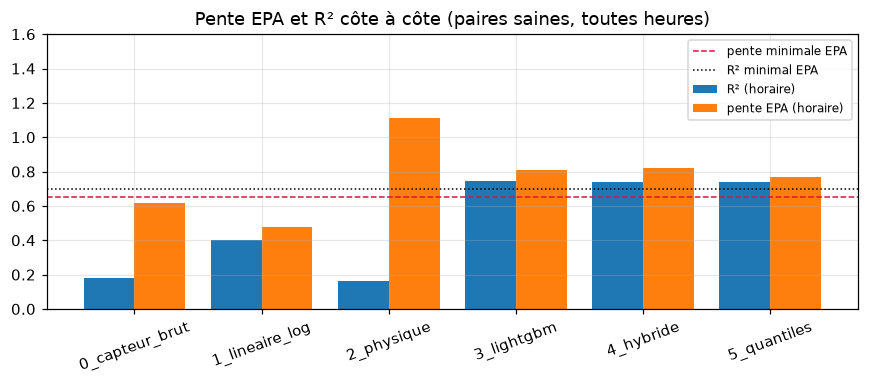

In [4]:
runs = results.children(settings, "echelle_de_modeles", FULL)
fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(runs.height)
ax.bar(x - 0.2, runs["hourly_saines_r2"], width=0.4, label="R² (horaire)")
ax.bar(x + 0.2, runs["hourly_saines_slope"], width=0.4, label="pente EPA (horaire)")
ax.axhline(0.65, color="crimson", ls="--", lw=1, label="pente minimale EPA")
ax.axhline(0.70, color="k", ls=":", lw=1, label="R² minimal EPA")
ax.set_xticks(x, runs["run"], rotation=20)
ax.set_ylim(0, 1.6)
ax.legend(fontsize=8)
ax.set_title("Pente EPA et R² côte à côte (paires saines, toutes heures)")
fig.tight_layout()
fig.savefig(FIG_DIR / "06_pente_vs_r2.png")
cols = ["run"] + [c for c in runs.columns if c.startswith(("interval_", "seconds_"))]
runs.select(cols).with_columns(pl.col(pl.Float64).round(3))

**Ce qu'on observe.** 
Les chiffres ci-dessous sont en horaire, paires saines, sauf mention contraire.

- **0. Capteur brut** : RMSE 11,0 µg/m³, $R^2$ 0,18 ; 24,8 % des paires passent les cibles EPA en horaire et 39,1 % en
  journalier.
- **1. Linéaire en log** : le RMSE est presque divisé par deux (6,0), **mais** la part des paires EPA tombe à 11,8 %.
  C'est exactement le mécanisme de la section 1 : le modèle est juste en moyenne mais resserré, avec une pente 0,48
  pour un $R^2$ de 0,40. L'échelon 1 bat l'échelon 0 sur l'erreur (RMSE, MAE), pas sur la pente : il corrige le biais
  moyen sans rien apprendre sur la dynamique propre à chaque capteur.
- **2. Physique** : sa pente est la seule proche de 1 (1,11), car ce n'est pas une régression : $a$ et $\kappa$
  redressent le gain sans resserrer. Elle donne 26,4 % de paires EPA, mais un RMSE de 19,5. En multipliant le brut par
  $a \approx 2{,}4$, elle multiplie aussi les pics parasites du capteur. Elle ne bat pas l'échelon 1 en RMSE : c'est
  une **variable**, pas un produit.
- **3. LightGBM** : c'est le grand saut. RMSE 3,95, $R^2$ 0,74, pente 0,81 ; 76,7 % des paires passent en horaire et
  85,6 % en journalier. La pente reste proche du $R^2$, comme prévu.
- **4. Hybride** (résidu de la physique) : il fait jeu égal sur les paires saines (RMSE 4,00, 78,0 % en horaire,
  84,4 % en journalier) mais s'effondre sur **toutes paires** (RMSE 6,52 et $R^2$ 0,48, contre 4,30 et 0,70).
  Partir de la physique, c'est hériter de ses pics sur les capteurs abîmés. Il est **rejeté pour manque de robustesse**.
- **5. Quantiles** : la médiane vaut LightGBM (RMSE 3,95), mais l'intervalle 10–90 % ne contient la référence que
  **62 %** du temps au lieu de 80 % (largeur médiane 4 µg/m³). Les quantiles sont appris sur les stations
  d'entraînement et ne voient pas le biais propre à une station nouvelle : l'intervalle est trop étroit. Il est
  inutilisable tel quel ; une calibration par station (conformal) est à prévoir.
- **Avec / sans voisins** (LightGBM, paires saines) : avec voisins, RMSE 3,53 et 84,5 % / 91,4 % de paires EPA
  (horaire / journalier) ; sans voisins, RMSE 5,24 et 44,4 % / 59,5 %. Sur toutes paires sans voisins : RMSE 6,18,
  38,3 % / 50,4 %.

## 3. Échelle log ou µg/m³ (sous-échantillon, mêmes plis)

**Ce qu'on fait.** Le même LightGBM, entraîné une fois sur $\ln$ référence (retour par la correction de Duan, calculée
pli par pli sur l'entraînement) et une fois directement en µg/m³ (erreur quadratique).

**Pourquoi.** Le log stabilise la variance d'une erreur multiplicative (notebook 04), mais un modèle en log minimise
une erreur **relative** alors que les cibles EPA (RMSE, pente) sont en µg/m³. Seule la mesure tranche.

In [5]:
both("echelle_log_vs_lineaire", SUB, metrics=("rmse", "mae", "r2", "slope", "intercept", "pct_epa_all"))

run,hourly_saines_rmse,hourly_saines_mae,hourly_saines_r2,hourly_saines_slope,hourly_saines_intercept,hourly_saines_pct_epa_all,hourly_toutes_rmse,…,daily_saines_intercept,daily_saines_pct_epa_all,daily_toutes_rmse,daily_toutes_mae,daily_toutes_r2,daily_toutes_slope,daily_toutes_intercept,daily_toutes_pct_epa_all
str,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64
"""cible_log""",4.3,2.55,0.7,0.79,1.91,70.53,4.34,…,1.26,82.22,3.41,2.15,0.75,0.84,1.3,80.58
"""cible_ugm3""",4.22,2.57,0.71,0.79,2.28,72.63,4.31,…,1.68,84.44,3.38,2.19,0.75,0.84,1.73,83.5


**Ce qu'on observe.** 
En µg/m³ : RMSE 4,22 contre 4,30 en log, et 72,6 % / 84,4 % de paires EPA contre 70,5 % / 82,2 % ; la pente est
identique (0,79). Le log optimise une erreur relative, qui donne autant de poids à 2 contre 3 µg/m³ qu'à 20 contre
30 µg/m³. Or les cibles EPA sont en µg/m³. **On retient la cible en µg/m³** (sans correction de Duan, inutile ici).
Attention : sur le sous-échantillon, 1 paire vaut 1,05 point de « % EPA » (95 paires saines notées). Les écarts de 1 à
3 points sont donc de 1 à 3 paires. La section 10 montre que, sur le volume complet, ce choix est moins net pour les
capteurs abîmés.

## 4. Ablation : que vaut chaque famille de variables ?

**Ce qu'on fait.** On retire une famille à la fois et on mesure la dégradation par rapport au modèle complet.

**Pourquoi.** Une famille dont le retrait ne change rien peut être abandonnée ; une famille dont le retrait dégrade
beaucoup est indispensable. Le voisinage citoyen est la famille la plus liée à l'erreur, mais une heure sur cinq n'a
pas 3 voisins valides : le produit doit aussi marcher sans.

In [6]:
ablation_runs = results.children(settings, "ablation", SUB)
base = ablation_runs.filter(pl.col("run") == "toutes_les_familles").row(0, named=True)
ablation_runs.select(
    "run",
    rmse=pl.col("hourly_saines_rmse").round(3),
    delta_rmse=(pl.col("hourly_saines_rmse") - base["hourly_saines_rmse"]).round(3),
    r2=pl.col("hourly_saines_r2").round(3),
    epa_horaire=pl.col("hourly_saines_pct_epa_all").round(1),
    epa_journalier=pl.col("daily_saines_pct_epa_all").round(1),
    rmse_avec_voisins=pl.col("hourly_saines_avec_voisins_rmse").round(3),
    rmse_sans_voisins=pl.col("hourly_saines_sans_voisins_rmse").round(3),
).sort("delta_rmse", descending=True)

run,rmse,delta_rmse,r2,epa_horaire,epa_journalier,rmse_avec_voisins,rmse_sans_voisins
str,f64,f64,f64,f64,f64,f64,f64
"""sans_voisinage citoyen""",5.189,0.889,0.591,54.7,67.8,5.035,5.67
"""sans_dynamique (passé)""",4.47,0.17,0.683,68.4,81.1,3.848,6.087
"""sans_temps""",4.407,0.107,0.689,69.5,83.3,3.852,5.878
"""sans_météo officielle""",4.357,0.057,0.694,70.5,85.6,3.876,5.661
"""sans_capteur brut""",4.347,0.046,0.695,68.4,84.4,3.791,5.815
"""toutes_les_familles""",4.301,0.0,0.703,70.5,82.2,3.742,5.77
"""sans_contexte""",4.3,-0.0,0.703,68.4,83.3,3.749,5.755
"""sans_modèle physique""",4.298,-0.003,0.703,70.5,82.2,3.74,5.766
"""sans_sonde locale (secondaire)""",4.273,-0.028,0.707,71.6,84.4,3.728,5.713


**Les heures sans voisins.** LightGBM accepte les valeurs manquantes : à chaque coupure d'un arbre, il apprend de
quel côté envoyer une valeur absente. On le vérifie : sur les **heures sans voisins**, le modèle complet (qui voit
« voisinage manquant ») doit faire au moins aussi bien que le modèle entraîné **sans** la famille voisinage.

**Ce qu'on fait.** On joint les prédictions hors pli des deux modèles heure par heure et on compare leur RMSE selon
que l'heure a des voisins ou non.

In [7]:
full_run = ablation_runs.filter(pl.col("run") == "toutes_les_familles")["run_id"][0]
no_nb_run = ablation_runs.filter(pl.col("run") == "sans_voisinage citoyen")["run_id"][0]
with_nb = pl.read_parquet(results.artifact(settings, full_run, "oof_predictions.parquet"))
without_nb = pl.read_parquet(results.artifact(settings, no_nb_run, "oof_predictions.parquet"))
both_models = with_nb.join(
    without_nb.select("pair_id", "hour", prediction_sans=pl.col("prediction")), on=["pair_id", "hour"]
)
both_models.filter(pl.col("sane_pair")).group_by("has_neighbours").agg(
    heures=pl.len(),
    rmse_modèle_complet=((pl.col("prediction") - pl.col("reference")) ** 2).mean().sqrt().round(3),
    rmse_modèle_sans_voisinage=((pl.col("prediction_sans") - pl.col("reference")) ** 2)
    .mean()
    .sqrt()
    .round(3),
).sort("has_neighbours")

has_neighbours,heures,rmse_modèle_complet,rmse_modèle_sans_voisinage
bool,u32,f32,f32
false,238717,5.77,5.67
true,786947,3.742,5.035


**Ce qu'on observe.** 
- **Le voisinage citoyen écrase tout** : le retirer fait passer le RMSE de 4,30 à 5,19 (+21 %) et les paires EPA de
  70,5 % à 54,7 % en horaire. Viennent ensuite la dynamique passée (+4 %), le temps (+2,5 %), la météo officielle
  (+1,3 %) et le capteur brut (+1,1 %).
- **Sonde locale retirée** : sans elle, le RMSE vaut 4,27 au lieu de 4,30, et les paires EPA 71,6 % au lieu de 70,5 %
  en horaire, 84,4 % au lieu de 82,2 % en journalier. Cette sonde n'apporte rien que l'humidité officielle n'apporte
  déjà, et elle meurt souvent (notebook 02). La retirer **simplifie le produit** : plus besoin de DHT22.
- **Familles neutres** : sans « capteur », le RMSE baisse un peu (−0,03) mais les paires EPA aussi (68,4 %) ; la
  famille est gardée (âge du capteur, utile pour la dérive à l'étape 7). Sans « modèle physique », rien ne change :
  les arbres la reconstruisent à partir du brut et de l'humidité. On la garde pour l'interprétation.
- **Limite de la méthode** : retirer une famille à la fois sous-estime les familles **redondantes**. Le brut et la
  physique portent la même information, donc chacune paraît peu utile seule.
- **Valeurs manquantes** : sur les heures sans voisins, le modèle complet fait 5,77 contre 5,67 pour un modèle appris
  sans la famille voisinage. LightGBM gère bien l'absence, sans effondrement, mais pas de façon optimale (≈ 2 % de
  perte). Un modèle dédié aux heures sans voisins gagnerait ≈ 0,1 µg/m³ (piste pour l'étape 7). Avec voisins, l'écart
  est de 3,74 contre 5,04.

## 5. La contrainte monotone sur le PM brut

**Ce qu'on fait.** On impose à LightGBM qu'à valeurs égales des autres variables, une mesure brute plus élevée
(`pm25_mean`, `pm25_median`, `log_pm25` et l'estimation physique qui en découle) ne fasse **jamais baisser** la
prédiction.

**Pourquoi.** Sans contrainte, un modèle peut apprendre des « creux » locaux, par exemple dans une zone de
concentrations rares : en service, un capteur qui monte ferait baisser la valeur corrigée. C'est physiquement absurde
et difficile à défendre devant un client. On la garde si la perte est négligeable.

In [8]:
both("contrainte_monotone", SUB, metrics=("rmse", "mae", "r2", "slope", "pct_epa_all"))

run,hourly_saines_rmse,hourly_saines_mae,hourly_saines_r2,hourly_saines_slope,hourly_saines_pct_epa_all,hourly_toutes_rmse,hourly_toutes_mae,…,daily_saines_r2,daily_saines_slope,daily_saines_pct_epa_all,daily_toutes_rmse,daily_toutes_mae,daily_toutes_r2,daily_toutes_slope,daily_toutes_pct_epa_all
str,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64
"""sans_contrainte""",4.3,2.55,0.7,0.79,70.53,4.34,2.57,…,0.75,0.85,82.22,3.41,2.15,0.75,0.84,80.58
"""avec_contrainte""",4.29,2.54,0.7,0.79,70.53,4.33,2.56,…,0.76,0.85,83.33,3.4,2.14,0.75,0.84,82.52


**Ce qu'on observe.** 
Avec la contrainte, RMSE 4,29 contre 4,30 ; les paires EPA horaires sont identiques (70,5 %), et 83,3 % contre 82,2 %
en journalier. La perte est nulle : **la contrainte est gardée**. Elle garantit qu'un capteur qui monte ne fait jamais
baisser la valeur corrigée.

## 6. Entraîner avec ou sans les paires invérifiables

**Ce qu'on fait.** Le même modèle, entraîné sur les paires saines seulement, puis sur toutes les paires (invérifiables
comprises), évalué sur les mêmes paires de test.

**Pourquoi.** Les invérifiables sont surtout des capteurs défectueux (notebook 04) : les apprendre pourrait abîmer le
modèle… ou au contraire lui apprendre à reconnaître un capteur abîmé.

In [9]:
both("paires_inverifiables", SUB, metrics=("rmse", "r2", "slope", "pct_epa_all"))

run,hourly_saines_rmse,hourly_saines_r2,hourly_saines_slope,hourly_saines_pct_epa_all,hourly_toutes_rmse,hourly_toutes_r2,hourly_toutes_slope,…,daily_saines_rmse,daily_saines_r2,daily_saines_slope,daily_saines_pct_epa_all,daily_toutes_rmse,daily_toutes_r2,daily_toutes_slope,daily_toutes_pct_epa_all
str,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64
"""entrainement_paires_saines""",4.3,0.7,0.79,70.53,4.34,0.7,0.77,…,3.38,0.75,0.85,82.22,3.41,0.75,0.84,80.58
"""entrainement_toutes_paires""",4.28,0.71,0.8,73.68,4.31,0.71,0.79,…,3.36,0.76,0.87,84.44,3.37,0.76,0.86,83.5


**Ce qu'on observe.** 
Entraîner aussi sur les paires invérifiables améliore légèrement les résultats : RMSE 4,28 contre 4,30 sur les paires
saines, et 4,31 contre 4,34 sur toutes paires ; paires EPA 73,7 % contre 70,5 % en horaire (3 paires du
sous-échantillon). Le modèle semble apprendre à reconnaître un capteur abîmé. On garde la décision de l'étape 5 (on
n'apprend pas sur des paires qu'on n'a pas pu vérifier), mais c'est une **proposition pour l'étape 7**.

## 7. Sensibilité au seuil X des mois-sondes « morts »

**Ce qu'on fait.** L'humidité locale (variable secondaire) est recalculée avec X = 0,1, 0,3 et 0,5 (part d'heures en
défaut au-delà de laquelle un mois de sonde est jugé « mort », notebook 02), puis le modèle est réentraîné.

**Pourquoi.** X = 0,3 a été choisi à l'étape 3 sur des arguments de qualité de donnée ; on vérifie que le modèle n'y
est pas sensible.

In [10]:
both("sensibilite_X", SUB, metrics=("rmse", "r2", "pct_epa_all"))

run,hourly_saines_rmse,hourly_saines_r2,hourly_saines_pct_epa_all,hourly_toutes_rmse,hourly_toutes_r2,hourly_toutes_pct_epa_all,daily_saines_rmse,daily_saines_r2,daily_saines_pct_epa_all,daily_toutes_rmse,daily_toutes_r2,daily_toutes_pct_epa_all
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""X_0.1""",4.32,0.7,70.53,4.35,0.7,68.52,3.4,0.75,83.33,3.42,0.75,81.55
"""X_0.3""",4.3,0.7,70.53,4.34,0.7,68.52,3.38,0.75,82.22,3.41,0.75,80.58
"""X_0.5""",4.29,0.71,71.58,4.33,0.7,69.44,3.36,0.76,84.44,3.39,0.75,82.52


**Ce qu'on observe.** 
Avec X = 0,1, 0,3 et 0,5, le RMSE vaut 4,32, 4,30 et 4,29 : l'effet est négligeable. Le seuil X ne sert plus qu'à
l'humidité locale, retirée du modèle final.

## 8. Recalibrer la pente ?

**Ce qu'on fait.** Si la pente bloque les cibles, on peut « déresserrer » les prédictions :
$\hat y' = (\hat y - b)/s$, où $\hat y = s\,y + b$ est ajusté sur des prédictions **hors pli des plis d'entraînement**
(validation croisée interne par station : le pli de test n'est jamais utilisé, et les prédictions d'entraînement ne sont
pas des prédictions sur des données apprises).

**Pourquoi.** C'est le compromis classique entre **prédiction** (erreur quadratique minimale, pente ≈ R²) et
**étalonnage** (pente 1, mais dispersion et RMSE plus grandes).

In [11]:
both("recalibration", SUB, metrics=("rmse", "r2", "slope", "intercept", "pct_epa_all"))

run,hourly_saines_rmse,hourly_saines_r2,hourly_saines_slope,hourly_saines_intercept,hourly_saines_pct_epa_all,hourly_toutes_rmse,hourly_toutes_r2,…,daily_saines_slope,daily_saines_intercept,daily_saines_pct_epa_all,daily_toutes_rmse,daily_toutes_r2,daily_toutes_slope,daily_toutes_intercept,daily_toutes_pct_epa_all
str,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64
"""sans_recalibration""",4.3,0.7,0.79,1.91,70.53,4.34,0.7,…,0.85,1.26,82.22,3.41,0.75,0.84,1.3,80.58
"""recalibration_hors_pli""",5.12,0.7,1.01,-0.11,71.58,5.11,0.7,…,1.1,-0.95,75.56,4.21,0.75,1.08,-0.9,74.76


**Ce qu'on observe.** 
La recalibration remplit son contrat sur la pente (0,79 → 1,01, ordonnée 1,91 → −0,11), mais le RMSE passe de 4,30 à
5,12 et les paires EPA journalières de 82,2 % à 75,6 % (+1 paire seulement en horaire). C'est le compromis annoncé :
« déresserrer », c'est aussi amplifier l'erreur. **Elle est rejetée.** Ce qui bloque les cibles n'est pas la pente
(0,81 pour LightGBM, déjà dans [0,65 ; 1,35]) mais le $R^2$ des heures sans voisins.

## 9. Optuna : les hyperparamètres

**Ce qu'on fait.** Essais de l'échantillonneur TPE (graine 42), chacun étant une validation croisée complète sur le
sous-échantillon, **avec exactement les mêmes plis par station et le même sous-échantillon que les autres études** ;
objectif : RMSE horaire des paires saines, en µg/m³. Chaque essai est un run MLflow imbriqué. La recherche, prévue sur
50 essais, a été **arrêtée à 15** : les essais s'allongeaient (jusqu'à 450 feuilles et 1 100 arbres) pour un gain de
0,08 µg/m³ (≈ 2 %), régulier sur les 5 plis mais marginal. Le meilleur essai (n° 14) est retenu tel quel.

**Pourquoi.** Savoir combien rapporte le réglage fin, comparé au travail sur les données et les variables.

{'learning_rate': 0.023318215769029375, 'num_leaves': 453, 'min_data_in_leaf': 59, 'feature_fraction': 0.7399523167914527, 'bagging_fraction': 0.7365333532822347, 'lambda_l2': 0.15053015799399602, 'num_boost_round': 1084, 'best_rmse': 4.219745635986328, 'trial': 'essai_14'}
shape: (2, 7)
┌─────────────────────┬────────────────────┬──────────────────────────┬──────────────────────────┬──────────────────────────┬──────────────────────────┬──────────────────────────┐
│ run                 ┆ hourly_saines_rmse ┆ fold0_hourly_saines_rmse ┆ fold1_hourly_saines_rmse ┆ fold2_hourly_saines_rmse ┆ fold3_hourly_saines_rmse ┆ fold4_hourly_saines_rmse │
│ ---                 ┆ ---                ┆ ---                      ┆ ---                      ┆ ---                      ┆ ---                      ┆ ---                      │
│ str                 ┆ f64                ┆ f64                      ┆ f64                      ┆ f64                      ┆ f64                      ┆ f64               

run,hourly_saines_rmse,hourly_saines_pct_epa_all,param_lgb_learning_rate,param_lgb_num_leaves,param_lgb_min_data_in_leaf,param_lgb_feature_fraction,param_lgb_bagging_fraction,param_lgb_bagging_freq,param_lgb_lambda_l2,param_lgb_max_bin,param_lgb_seed,param_lgb_deterministic,param_num_boost_round
str,f64,f64,str,str,str,str,str,str,str,str,str,str,str
"""essai_14""",4.219746,73.684211,"""0.023318215769029375""","""453""","""59""","""0.7399523167914527""","""0.7365333532822347""","""1""","""0.15053015799399602""","""255""","""42""","""True""","""1084"""
"""essai_13""",4.222584,73.684211,"""0.02240684101492362""","""389""","""77""","""0.8135921001981343""","""0.6495570039699504""","""1""","""0.020954853441210636""","""255""","""42""","""True""","""825"""
"""essai_12""",4.236969,72.631579,"""0.044783017330519974""","""482""","""142""","""0.7732390083984002""","""0.8449157763595554""","""1""","""0.23880053334623405""","""255""","""42""","""True""","""1042"""
"""essai_06""",4.24237,70.526316,"""0.021648036763001914""","""396""","""163""","""0.7975133706123891""","""0.6558555380447055""","""1""","""0.21301372721189443""","""255""","""42""","""True""","""601"""
"""essai_07""",4.271287,72.631579,"""0.030611488731000357""","""469""","""1771""","""0.9636993649385135""","""0.9474136752138245""","""1""","""0.47519373182795593""","""255""","""42""","""True""","""1282"""


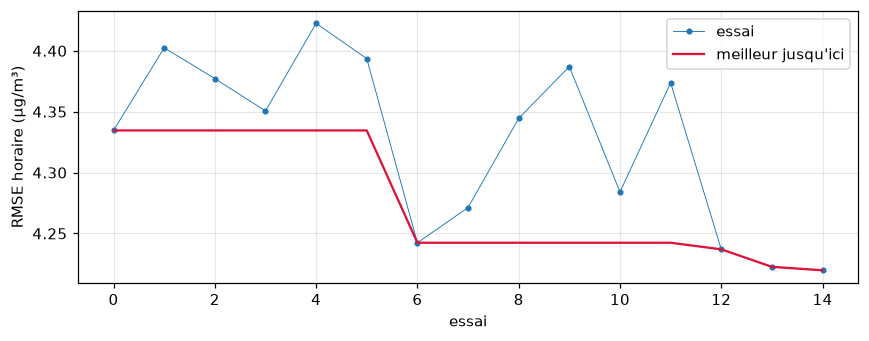

In [12]:
trials = results.children(settings, "optuna", SUB)
params = [c for c in trials.columns if c.startswith("param_lgb_") or c == "param_num_boost_round"]
best = (
    trials.sort("hourly_saines_rmse")
    .head(5)
    .select("run", "hourly_saines_rmse", "hourly_saines_pct_epa_all", *params)
)
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(np.arange(trials.height), trials["hourly_saines_rmse"], marker=".", lw=0.6, label="essai")
ax.plot(
    np.arange(trials.height),
    trials["hourly_saines_rmse"].cum_min(),
    color="crimson",
    label="meilleur jusqu'ici",
)
ax.set_xlabel("essai")
ax.set_ylabel("RMSE horaire (µg/m³)")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "06_optuna.png")
print(json.loads((settings.paths.gold.parent / "models" / "optuna_best.json").read_text()))
reference = results.children(settings, "ablation", SUB).filter(pl.col("run") == "toutes_les_familles")
folds = [f"fold{k}_hourly_saines_rmse" for k in range(5)]
print(
    pl.concat(
        [
            reference.select("run", "hourly_saines_rmse", *folds),
            trials.sort("hourly_saines_rmse").head(1).select("run", "hourly_saines_rmse", *folds),
        ]
    ).with_columns(pl.col(pl.Float64).round(3))
)
best

**Ce qu'on observe.** 
Le meilleur essai (n° 14, RMSE 4,22) bat le réglage par défaut (4,30) de 0,08 µg/m³ (**−1,9 %**). Il gagne sur 4 plis
et fait jeu égal sur le pli 3 (4,979 contre 4,973). Les meilleurs essais ont tous des arbres profonds (390 à 480
feuilles), peu de lignes par feuille (59 à 163) et un pas d'apprentissage bas (≈ 0,02) avec beaucoup d'arbres : c'est
pourquoi les essais s'allongeaient. Le réglage par défaut était raisonnable : **les hyperparamètres ne sont pas le
levier**.

### 9 bis. D'où vient la performance ?

**Ce qu'on fait.** On met sur le même axe ce que coûte le retrait de chaque famille de variables (ablation) et ce que
rapporte le réglage des hyperparamètres (Optuna), tous mesurés sur le même sous-échantillon et les mêmes plis.
**Pourquoi.** Pour savoir où investir l'effort : dans les données et les variables, ou dans le réglage du modèle.

effet,delta,pct
str,f64,f64
"""réglage Optuna (essai 14)""",-0.081,-1.9
"""retirer : capteur""",-0.034,-0.8
"""retirer : sonde locale (secondaire)""",-0.028,-0.6
"""retirer : modèle physique""",-0.003,-0.1
"""retirer : contexte""",-0.0,-0.0
"""retirer : capteur brut""",0.046,1.1
"""retirer : météo officielle""",0.057,1.3
"""retirer : temps""",0.107,2.5
"""retirer : dynamique (passé)""",0.17,4.0


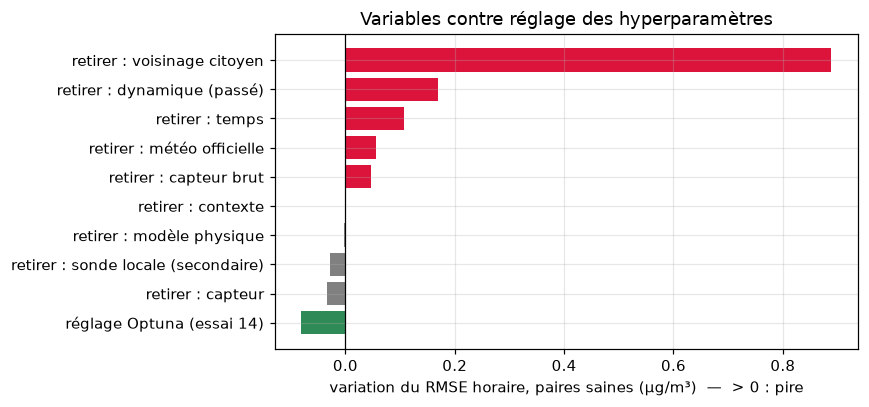

In [13]:
base_rmse = base["hourly_saines_rmse"]
effects = ablation_runs.filter(pl.col("run") != "toutes_les_familles").select(
    effet=pl.col("run").str.replace("sans_", "retirer : "), delta=pl.col("hourly_saines_rmse") - base_rmse
)
tuned = trials["hourly_saines_rmse"].min()
effects = pl.concat(
    [effects, pl.DataFrame({"effet": ["réglage Optuna (essai 14)"], "delta": [tuned - base_rmse]})]
).sort("delta")
fig, ax = plt.subplots(figsize=(8, 3.8))
colors = [
    "seagreen" if "Optuna" in e else ("crimson" if d > 0 else "grey")
    for e, d in zip(effects["effet"], effects["delta"], strict=True)
]
ax.barh(effects["effet"], effects["delta"], color=colors)
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("variation du RMSE horaire, paires saines (µg/m³)  —  > 0 : pire")
ax.set_title("Variables contre réglage des hyperparamètres")
fig.tight_layout()
fig.savefig(FIG_DIR / "06_donnees_vs_reglage.png")
effects.with_columns(pl.col("delta").round(3), pct=(100 * pl.col("delta") / base_rmse).round(1))

**Ce qu'on observe.** 
Le réglage Optuna rapporte 1,9 %. Retirer le voisinage coûte 20,7 %, retirer la dynamique passée 4,0 % et retirer les
variables de temps 2,5 %. À l'échelle de modèles, passer du linéaire en log à LightGBM avec toutes les variables
divise le RMSE par 1,5 (6,03 → 3,95) et fait passer les paires EPA de 12 % à 77 %. **La performance vient des données
et des variables** (surtout des capteurs voisins), pas du réglage fin.

## 10. Le modèle retenu, réentraîné sur le volume complet

**Ce qu'on fait.** Le réglage retenu (sections 3 à 9 : cible en µg/m³, contrainte monotone, sans la sonde locale, sans
recalibration) est réentraîné sur le volume complet, mêmes 5 plis, **deux fois** : avec les hyperparamètres par défaut et
avec ceux d'Optuna. On donne ses métriques (horaire et journalier, paires saines et toutes paires, avec et sans
voisins), le découpage par type de station et par méthode de mesure, et l'importance des variables.
**Pourquoi.** C'est le **chiffre de référence** de l'étape : 5 plis spatiaux, volume complet. Les hyperparamètres ont été
choisis sur ces mêmes plis (sous-échantillon) : le chiffre « Optuna » est donc très légèrement optimiste, d'au plus
l'écart entre les deux variantes.

In [14]:
final_runs = results.children(settings, "modele_final", FULL)
print(both("modele_final", FULL, metrics=("rmse", "mae", "r2", "slope", "intercept", "pct_epa_all")))
final = final_runs.filter(pl.col("run") == "final_reglages_optuna").row(0, named=True)
print({k.replace("param_final_", ""): v for k, v in final.items() if k.startswith("param_final_")})
summary_final = pl.read_csv(results.artifact(settings, final["run_id"], "summary.csv"))
summary_final.select(
    "résolution", "paires", "voisins", "n", "rmse", "mae", "r2", "slope", "intercept", "pairs", "pct_epa_all"
).with_columns(pl.col(pl.Float64).round(3))

shape: (2, 25)
┌──────────┬──────────┬──────────┬──────────┬──────────┬──────────┬──────────┬──────────┬───┬──────────┬──────────┬──────────┬──────────┬──────────┬──────────┬──────────┬─────────┐
│ run      ┆ hourly_s ┆ hourly_s ┆ hourly_s ┆ hourly_s ┆ hourly_s ┆ hourly_s ┆ hourly_t ┆ … ┆ daily_sa ┆ daily_sa ┆ daily_to ┆ daily_to ┆ daily_to ┆ daily_to ┆ daily_to ┆ daily_t │
│ ---      ┆ aines_rm ┆ aines_ma ┆ aines_r2 ┆ aines_sl ┆ aines_in ┆ aines_pc ┆ outes_rm ┆   ┆ ines_int ┆ ines_pct ┆ utes_rms ┆ utes_mae ┆ utes_r2  ┆ utes_slo ┆ utes_int ┆ outes_p │
│ str      ┆ se       ┆ e        ┆ ---      ┆ ope      ┆ tercept  ┆ t_epa_al ┆ se       ┆   ┆ ercept   ┆ _epa_all ┆ e        ┆ ---      ┆ ---      ┆ pe       ┆ ercept   ┆ ct_epa_ │
│          ┆ ---      ┆ ---      ┆ f64      ┆ ---      ┆ ---      ┆ l        ┆ ---      ┆   ┆ ---      ┆ ---      ┆ ---      ┆ f64      ┆ f64      ┆ ---      ┆ ---      ┆ all     │
│          ┆ f64      ┆ f64      ┆          ┆ f64      ┆ f64      ┆ ---      ┆ f

résolution,paires,voisins,n,rmse,mae,r2,slope,intercept,pairs,pct_epa_all
str,str,str,f64,f64,f64,f64,f64,f64,f64,f64
"""hourly""","""saines""","""toutes""",4.674183e6,3.843,2.35,0.756,0.816,2.009,459.0,79.739
"""daily""","""saines""","""toutes""",188681.0,2.978,1.924,0.805,0.873,1.47,443.0,85.327
"""hourly""","""saines""","""avec_voisins""",3.700818e6,3.391,2.128,0.81,0.857,1.66,375.0,88.267
"""daily""","""saines""","""avec_voisins""",149021.0,2.564,1.729,0.856,0.907,1.178,362.0,91.989
"""hourly""","""saines""","""sans_voisins""",973365.0,5.214,3.192,0.554,0.655,3.296,133.0,42.105
"""daily""","""saines""","""sans_voisins""",37624.0,4.237,2.687,0.605,0.733,2.582,111.0,58.559
"""hourly""","""toutes""","""toutes""",5.558171e6,4.375,2.544,0.695,0.793,2.299,549.0,74.681
"""daily""","""toutes""","""toutes""",223951.0,3.516,2.1,0.74,0.852,1.732,529.0,81.853
"""hourly""","""toutes""","""avec_voisins""",4.365221e6,3.538,2.219,0.796,0.847,1.801,445.0,84.27


**Ce qu'on fait.** Erreur du modèle retenu par type de station, par méthode de mesure de la station et selon la présence
de voisins, séparément pour les paires saines et invérifiables (`sane_pair`).
**Pourquoi.** Une moyenne globale peut cacher une catégorie où le modèle échoue.

In [15]:
oof = pl.read_parquet(results.artifact(settings, final["run_id"], "oof_predictions.parquet"))
error = pl.col("prediction") - pl.col("reference")
breakdown = []
for column in ("station_type", "method_class", "has_neighbours"):
    breakdown.append(
        oof.group_by("sane_pair", column)
        .agg(
            heures=pl.len(),
            paires=pl.col("pair_id").n_unique(),
            rmse=(error**2).mean().sqrt(),
            mae=error.abs().mean(),
            r2=pl.corr("prediction", "reference") ** 2,
        )
        .rename({column: "tranche"})
        .with_columns(découpage=pl.lit(column), tranche=pl.col("tranche").cast(pl.String))
    )
pl.concat(breakdown).select(
    "découpage", "tranche", "sane_pair", "heures", "paires", "rmse", "mae", "r2"
).sort("découpage", "tranche", "sane_pair").with_columns(pl.col(pl.Float64).round(3))

découpage,tranche,sane_pair,heures,paires,rmse,mae,r2
str,str,bool,u32,u32,f32,f32,f32
"""has_neighbours""","""false""",false,219585,88,10.730706,6.133183,0.083225
"""has_neighbours""","""false""",true,973365,343,5.214391,3.192059,0.553884
"""has_neighbours""","""true""",false,664403,91,4.264703,2.727649,0.719809
"""has_neighbours""","""true""",true,3700818,382,3.3912,2.127974,0.810155
"""method_class""","""beta""",false,31100,6,6.368871,3.922294,0.525409
"""method_class""","""beta""",true,261586,21,3.104037,1.823271,0.832086
"""method_class""","""nephelometry_beta""",false,85917,13,8.234447,4.188377,0.223694
"""method_class""","""nephelometry_beta""",true,652451,61,4.239641,2.601917,0.654526
"""method_class""","""optical""",false,704551,89,6.32038,3.477774,0.469071


**Ce qu'on fait.** Part du gain total de LightGBM apportée par chaque variable, moyennée sur les 5 plis.
**Pourquoi.** Vérifier que le modèle s'appuie sur des variables physiquement sensées, et non sur un identifiant déguisé.

feature,gain
str,f64
"""neighbour_median""",0.3777
"""log_physics_pm25""",0.1198
"""physics_pm25""",0.0945
"""pm10_mean""",0.0542
"""neighbour_log_ratio""",0.0537
"""pm25_median""",0.0359
"""sensor_weather_km""",0.028
"""dew_point""",0.0233
"""distance_km""",0.0166


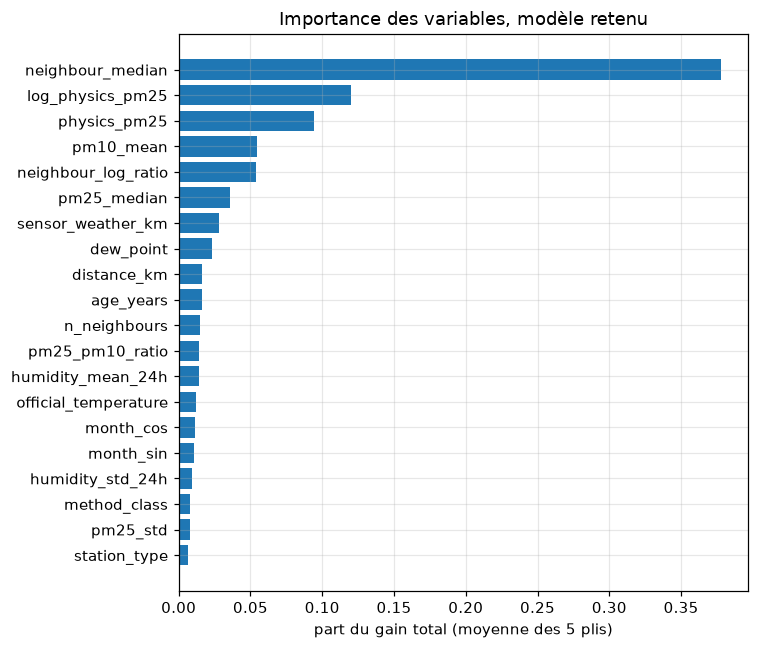

In [16]:
importance = pl.read_csv(results.artifact(settings, final["run_id"], "importance.csv"))
fig, ax = plt.subplots(figsize=(7, 6))
top = importance.head(20).reverse()
ax.barh(top["feature"], top["gain"])
ax.set_xlabel("part du gain total (moyenne des 5 plis)")
ax.set_title("Importance des variables, modèle retenu")
fig.tight_layout()
fig.savefig(FIG_DIR / "06_importance.png")
importance.head(15).with_columns(pl.col("gain").round(4))

**Ce qu'on observe.** 
- **Chiffre de référence** (Optuna, 5 plis, volume complet, paires saines) : RMSE horaire **3,84 µg/m³**, MAE 2,35,
  $R^2$ 0,76, pente 0,82, ordonnée 2,0 ; **79,7 %** des paires passent les cibles EPA en horaire et **85,3 %** en
  journalier. Sur toutes paires : RMSE 4,38, 74,7 % et 81,9 %.
- **Avec / sans voisins** (paires saines) : avec voisins, RMSE 3,39 et **88,3 % / 92,0 %** de paires EPA ; sans
  voisins (21 % des heures), RMSE **5,21** et **42,1 % / 58,6 %**. Sur toutes paires sans voisins : RMSE 6,59 et
  36,4 % / 49,6 %. C'est **la principale limite du produit**.
- **Réglage par défaut contre Optuna, volume complet** : 3,91 contre 3,84 (−1,8 %) ; paires EPA horaires 77,3 % contre
  79,7 %, journalières identiques (85,3 %). Les hyperparamètres ont été choisis sur ces mêmes plis (sous-échantillon),
  donc le chiffre Optuna est légèrement optimiste. Cet optimisme est **borné par l'écart entre les deux variantes**
  (≤ 0,07 µg/m³). Une validation imbriquée (Optuna relancé dans chacun des 5 plis) aurait coûté ≈ 3 h ; elle n'a pas été faite.
- **Point de vigilance** : par rapport à l'échelon 3 (log, sans contrainte, avec sonde, réglages par défaut), le
  modèle retenu gagne sur les paires saines (3,84 contre 3,95) mais **perd sur toutes paires** (4,38 contre 4,30 ; sans
  voisins, 6,59 contre 6,18). Le gain d'Optuna est hors de cause : la variante par défaut fait 4,45. Le recul vient
  donc de la cible en µg/m³, de la contrainte ou du retrait de la sonde, qui ont été choisis sur le sous-échantillon,
  où cet effet n'apparaissait pas (4,31 contre 4,34). Hypothèse : une erreur quadratique en µg/m³ suit davantage les
  pics des capteurs abîmés. Ce n'est pas tranché ; c'est noté au journal.
- **Découpages** (paires saines) : stations de fond et de trafic au même niveau (RMSE 3,80) ; stations industrielles
  plus difficiles (5,89, 8 paires seulement). Par méthode : bêta 3,10, optique 3,68, néphélométrie + bêta 4,24, TEOM 5,34
  (le retard d'une demi-heure du TEOM coûte encore). Le pire cas est le capteur invérifiable sans voisins : RMSE 10,7,
  $R^2$ 0,08.
- **Importance** : la médiane des voisins porte 38 % du gain, la physique (log et µg/m³) 21 %, puis le PM10 et l'écart
  au voisinage (≈ 5 % chacun).

## 11. Le score de santé, validé sur des données qu'il n'a pas vues

**Ce qu'on fait.** Pour chaque pli : on choisit le seuil qui maximise le score F1 (compromis précision–rappel) sur les
paires des 4 autres plis, puis on mesure précision et rappel sur le pli restant. Enfin, le seuil choisi sur toute
l'Allemagne est appliqué tel quel à la France, sans recalibrer.

**Pourquoi.** Au notebook 05, le seuil 0,1 avait été fixé en regardant toutes les paires : ses performances étaient
donc un peu optimistes.

In [17]:
pairs = pl.read_parquet(settings.paths.gold / "pairs.parquet")
per_fold, transfer = threshold_cv(pairs, np.round(np.linspace(0.0, 0.5, 51), 3), settings.study.main_country)
print(
    "France, seuil choisi sur l'Allemagne :",
    {k: (round(v, 3) if isinstance(v, float) else v) for k, v in transfer.items()},
)
per_fold.with_columns(pl.col(pl.Float64).round(3))

France, seuil choisi sur l'Allemagne : {'threshold': 0.19, 'pairs': 50, 'flagged': 6, 'true_positives': 3, 'precision': np.float64(0.5), 'recall': np.float64(0.25), 'f1': np.float64(0.333)}


fold,threshold,pairs,flagged,true_positives,precision,recall,f1
i64,f64,i64,i64,i64,f64,f64,f64
0,0.27,166,21,10,0.476,0.526,0.5
1,0.19,200,21,15,0.714,0.5,0.588
2,0.17,212,30,25,0.833,0.595,0.694
3,0.29,196,33,18,0.545,0.692,0.61
4,0.19,175,20,13,0.65,0.481,0.553


**Ce qu'on fait.** Pour comparaison, le seuil fixe 0,1 du notebook 05, en Allemagne et en France.
**Pourquoi.** Un seuil bas signale moins de paires mais avec plus de certitude : c'est le choix « prudent » d'un produit
qui ne veut pas accuser à tort le capteur d'un client.

In [18]:
from aircalib.evaluation.health import confusion

scored = pairs.drop_nulls("health_change_corr").with_columns(broken=~pl.col("sane_pair"))
fixed = settings.health.change_corr_min
pl.DataFrame(
    [
        {
            "pays": country,
            "paires_notées": part.height,
            "invérifiables": int(part["broken"].sum()),
            "seuil": fixed,
            **{
                k: (round(v, 3) if isinstance(v, float) else v)
                for k, v in confusion(
                    part["health_change_corr"].to_numpy(), part["broken"].to_numpy(), fixed
                ).items()
            },
        }
        for country, part in ((c, scored.filter(pl.col("country") == c)) for c in ("DE", "FR"))
    ]
)

pays,paires_notées,invérifiables,seuil,flagged,true_positives,precision,recall,f1
str,i64,i64,f64,i64,i64,f64,f64,f64
"""DE""",949,144,0.1,67,57,0.851,0.396,0.54
"""FR""",50,12,0.1,2,1,0.5,0.083,0.143


**Ce qu'on observe.** 
Les seuils choisis par F1 sur 4 plis vont de 0,17 à 0,29. Sur le pli tenu à l'écart, la précision va de 48 % à 83 %
(81 vrais positifs sur 125 signalements, soit **65 %**) et le rappel de 48 % à 69 % (81 sur 144, soit **56 %**). Le
transfert à la France est faible : avec le seuil 0,19 choisi sur l'Allemagne, 6 paires sont signalées dont 3 vraiment
abîmées sur 12 (précision 50 %, rappel 25 %), sur 50 paires notées seulement. Le seuil prudent 0,1 donne en Allemagne
85 % de précision pour 40 % de rappel, mais ne repère qu'une paire abîmée en France. Hypothèse, à vérifier à
l'étape 7 : un voisinage plus clairsemé en France rend le score plus bruité.

## 12. Temps de calcul

**Ce qu'on fait.** Somme des temps d'entraînement et de prédiction (5 plis) par étude, lus dans MLflow.
**Pourquoi.** Le coût de calcul fait partie du choix d'un modèle (MacBook, tout en local).

In [19]:
rows = []
for parent, scope in (
    ("echelle_de_modeles", FULL),
    ("ablation", SUB),
    ("contrainte_monotone", SUB),
    ("recalibration", SUB),
    ("optuna", SUB),
    ("modele_final", FULL),
):
    runs = results.children(settings, parent, scope)
    rows.append(
        {
            "étude": parent,
            "volume": scope,
            "runs": runs.height,
            "entraînement_min": round(runs["seconds_fit_total"].sum() / 60, 1),
            "prédiction_min": round(runs["seconds_predict_total"].sum() / 60, 1),
        }
    )
pl.DataFrame(rows)

étude,volume,runs,entraînement_min,prédiction_min
str,str,i64,f64,f64
"""echelle_de_modeles""","""complet""",6,14.8,1.4
"""ablation""","""sous-échantillon""",10,10.6,0.6
"""contrainte_monotone""","""sous-échantillon""",2,2.2,0.1
"""recalibration""","""sous-échantillon""",2,6.3,0.1
"""optuna""","""sous-échantillon""",15,33.9,2.3
"""modele_final""","""complet""",2,10.1,1.4


**Ce qu'on observe.** 
Sur MacBook, tout en local : 15 min d'entraînement pour l'échelle complète (dont 8,6 min pour les quantiles),
10,6 min pour l'ablation, 34 min pour les 15 essais Optuna et 10 min pour le modèle final (2,6 min par défaut, 7,5 min
avec les réglages Optuna, des arbres plus profonds et 1 084 itérations). La prédiction est rapide (3 à 13 s par
pli pour plus d'un million d'heures). Le réglage Optuna triple le temps d'entraînement pour 1,8 % de gain.

## 13. Bilan de l'étape 6

**Modèle retenu** : LightGBM en µg/m³, 45 variables (sans la sonde locale), contrainte monotone sur le PM brut et la
physique, réglages Optuna (essai 14), sans recalibration.

**Résultats** (paires saines / toutes paires), calculés sur les 5 plis par station et le volume complet :

| | RMSE horaire | % paires EPA horaire | % paires EPA journalier |
|---|---|---|---|
| Capteur brut | 11,03 / 30,64 | 24,8 / 20,8 | 39,1 / 32,7 |
| Modèle retenu, toutes heures | 3,84 / 4,38 | 79,7 / 74,7 | 85,3 / 81,9 |
| … heures avec voisins (79 %) | 3,39 / 3,54 | 88,3 / 84,3 | 92,0 / 90,2 |
| … heures sans voisins (21 %) | 5,21 / 6,59 | 42,1 / 36,4 | 58,6 / 49,6 |

**Ce qu'on retient.**

1. La performance vient des données et des variables, d'abord du **voisinage citoyen**. Le retirer coûte 21 % de
   RMSE ; le réglage des hyperparamètres rapporte 2 %.
2. **Limite principale** : sans voisins, le modèle reste loin des cibles EPA (42 % des paires saines en horaire).
3. La pente EPA d'un modèle quadratique suit son $R^2$. La recalibrer dégrade le RMSE sans débloquer les cibles.
4. L'hybride et l'intervalle quantile ne sont pas prêts : le premier n'est pas robuste aux capteurs abîmés, le second
   ne couvre que 62 % au lieu de 80 %.
5. Le chiffre Optuna est légèrement optimiste (≤ 0,07 µg/m³).
6. Sur toutes paires, le modèle retenu fait un peu moins bien que l'échelon 3 en log (4,38 contre 4,30) : c'est à
   surveiller.

**Étape 7** : test 2024 → 2025, test « distance » (bande 1,5–3 km), transfert vers la France ; pistes : modèle dédié
aux heures sans voisins, intervalle calibré par station, entraînement avec les paires invérifiables.